# Day 10: Embeddings and vector databases

Day 09 turned files into clean **chunks**. Today we make them **searchable by meaning**.

```
chunks → embed → index → vector DB  →  (Day 11: hybrid search)
```

| § | Topic |
|---|---|
| 1 | What is an embedding: numbers, shape, dimensions |
| 2 | **Why** embed: keyword search vs meaning search |
| 3 | **How** to embed: similarity, models, cost, shorter vectors |
| 4 | How an **index** is formed: flat, IVF, HNSW |
| 5 | Vector databases |
| 6 | **FAISS** |
| 7 | **Qdrant** |
| 8 | **Pinecone** |
| 9 | FAISS vs Qdrant vs Pinecone, in plain words |
| 10 | Recap |

Our data: the **198 BNS chunks** from the Kanoon.ai project (`kanoon-ai/data_ingestion/data/chunks/bns.jsonl`).

Needs `OPENAI_API_KEY` in `.env`. `PINECONE_API_KEY` only for §8.

In [2]:
import json, os, time, uuid
from pathlib import Path

import numpy as np
import pandas as pd
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv()
client = OpenAI()

CHUNKS_PATH = Path("../../kanoon-ai/data_ingestion/data/chunks/bns.jsonl")
CACHE = Path("cache")
CACHE.mkdir(exist_ok=True)

EMBED_MODEL = "text-embedding-3-small"          # checked 2026-10-26

def embed(texts, model=EMBED_MODEL):
    response = client.embeddings.create(model=model, input=texts)
    return np.array([d.embedding for d in response.data])

## 1. What is an embedding

**An embedding is a list of numbers that represents the meaning of a piece of text.** (Also images, audio, code.)

### 1.1 GPS coordinates, but for meaning

Every place on Earth has two numbers: latitude and longitude. **Close places have close numbers.**

In [3]:
cities = {"Delhi": [28.61, 77.21], "Gurugram": [28.46, 77.03], "Chennai": [13.08, 80.27]}

for a, b in [("Delhi", "Gurugram"), ("Delhi", "Chennai")]:
    print(f"{a} → {b}: {np.linalg.norm(np.subtract(cities[a], cities[b])):.2f}")

Delhi → Gurugram: 0.23
Delhi → Chennai: 15.83


An embedding does the same for **meaning**. Imagine we give every sentence 3 scores: how much it is about **food**, **money** and **law**:

In [4]:
toy = pd.DataFrame({
    "food":  [0.9, 0.8, 0.0, 0.1],
    "money": [0.1, 0.2, 0.9, 0.2],
    "law":   [0.0, 0.0, 0.1, 0.9],
}, index=["I ordered a pizza last night",
          "I got food delivered to my home",
          "The stock market fell sharply today",
          "Murder is punished with death or life imprisonment"])
toy

,food,money,law
I ordered a pizza last night,0.9,0.1,0.0
I got food delivered to my home,0.8,0.2,0.0
The stock market fell sharply today,0.0,0.9,0.1
Murder is punished with death or life imprisonment,0.1,0.2,0.9


Rows 1 and 2 have close numbers (same meaning, different words). Row 3 is far away.

A real model does this with **hundreds or thousands of numbers**, and it *learns* them from billions of sentences. Nobody decides what each number means.

### 1.2 A real embedding

In [5]:
sentences = list(toy.index)
vectors = embed(sentences)

print("one vector :", len(vectors[0]), "numbers")
print("first 8    :", vectors[0][:8].round(3))
print("all of them:", vectors.shape)

one vector : 1536 numbers
first 8    : [-0.017 -0.027 -0.073 -0.035 -0.002 -0.021 -0.017  0.056]
all of them: (4, 1536)


How close is each pair? (1 = same meaning, 0 = unrelated)

In [6]:
pd.DataFrame(vectors @ vectors.T, index=sentences, columns=[s[:18] + "…" for s in sentences]).round(2)

,I ordered a pizza …,I got food deliver…,The stock market f…,Murder is punished…
I ordered a pizza last night,1.00,0.49,0.23,0.06
I got food delivered to my home,0.49,1.00,0.14,0.03
The stock market fell sharply today,0.23,0.14,1.00,0.09
Murder is punished with death or life imprisonment,0.06,0.03,0.09,1.00


Pizza and food delivery are the closest pair, with almost no shared words. Murder is far from the stock market.

### 1.3 Numbers, shape and dimensions

In [7]:
print("smallest number:", vectors.min().round(3), "| biggest:", vectors.max().round(3))
print("length of each vector:", np.linalg.norm(vectors, axis=1).round(3))

smallest number: -0.096 | biggest: 0.12
length of each vector: [1. 1. 1. 1.]


- **Dimensions** = how many numbers in one vector. `text-embedding-3-small` gives **1,536**, `-large` gives **3,072**, a small local model gives 384.
- **Shape** = `(number of texts, dimensions)`. One text → `(1536,)`. Our 198 chunks → `(198, 1536)`.
- **Each number is small** (about −0.1 to 0.1) and the vector's **length is 1**: OpenAI normalises it (https://developers.openai.com/api/docs/guides/embeddings).
- **One number alone means nothing.** "Number 412 = food" is not true. Only the whole vector, compared with others, has meaning.
- **Vectors from different models can't be compared.** Each model has its own "map". Embed the documents and the question with the **same model**.

How much memory? Each number is a 4-byte float:

In [8]:
for n in [198, 100_000, 10_000_000]:
    print(f"{n:>12,} chunks × 1,536 dims × 4 bytes = {n * 1536 * 4 / 1e9:8.3f} GB")

         198 chunks × 1,536 dims × 4 bytes =    0.001 GB
     100,000 chunks × 1,536 dims × 4 bytes =    0.614 GB
  10,000,000 chunks × 1,536 dims × 4 bytes =   61.440 GB


10 million chunks need about **61 GB** just for the vectors. This is why vector DBs compress them (quantization, §4.4).

### 1.4 A picture of the meaning space

1,536 dimensions can't be drawn, so we squeeze them into 2 with **PCA**. Some detail is lost, but groups stay groups.

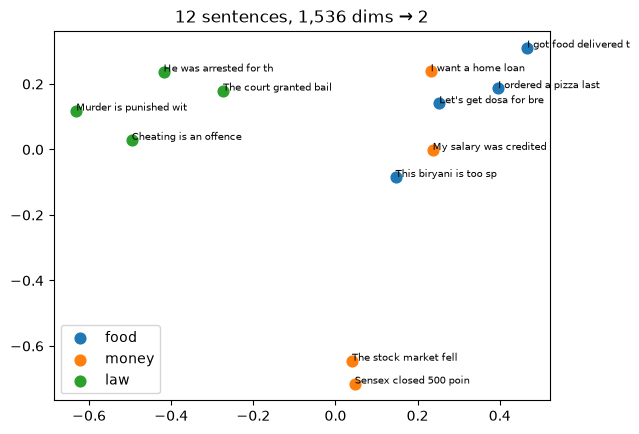

In [9]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

groups = {
    "food":  ["I ordered a pizza last night", "I got food delivered to my home", "This biryani is too spicy", "Let's get dosa for breakfast"],
    "money": ["The stock market fell sharply today", "My salary was credited this morning", "Sensex closed 500 points down", "I want a home loan"],
    "law":   ["Murder is punished with death or life imprisonment", "He was arrested for theft", "The court granted bail", "Cheating is an offence under the BNS"],
}
texts = [t for ts in groups.values() for t in ts]
points = PCA(n_components=2).fit_transform(embed(texts))

for i, (name, ts) in enumerate(groups.items()):
    xy = points[i * 4:(i + 1) * 4]
    plt.scatter(xy[:, 0], xy[:, 1], label=name, s=60)
    for (x, y), t in zip(xy, ts):
        plt.annotate(t[:22], (x, y), fontsize=7)
plt.legend(); plt.title("12 sentences, 1,536 dims → 2"); plt.show()

Three clear groups. **Search by meaning = find the nearest points.**

### 1.5 1,536 vs 3,072 dimensions

**Theory:** dimensions = how many numbers describe one text. More numbers = **more room** to keep apart things that are almost the same.

Describe two friends with numbers. With 2 numbers (height, weight) Rahul and Amit look identical. Add 2 more (age, city) and they separate:

In [ ]:
rahul = [170, 65, 22, 1]                         # height, weight, age, city (1 = Delhi, 2 = Bengaluru)
amit  = [170, 65, 35, 2]

print("2 dims:", np.linalg.norm(np.subtract(rahul[:2], amit[:2])), "→ look the same")
print("4 dims:", np.linalg.norm(np.subtract(rahul, amit)).round(2), "→ different people")

Real models work the same way, except **nobody names the dimensions**: the model learns them. `text-embedding-3-small` gives 1,536 numbers, `-large` gives 3,072.

Same question, same 4 sentences, both models:

In [ ]:
law = ["Murder is punished with death or imprisonment for life",
       "Theft is punished with imprisonment up to three years",
       "Robbery is punished with rigorous imprisonment up to ten years",
       "I ordered a pizza last night"]
question = "Is killing someone a crime?"

rows = {}
for model in ["text-embedding-3-small", "text-embedding-3-large"]:
    v = embed([question] + law, model)
    print(f"{model}: shape {v.shape}, {v.shape[1] * 4 / 1024:.0f} KB per 1,000 chunks... per chunk {v.shape[1] * 4:,} bytes")
    rows[model] = (v[1:] @ v[0]).round(3)
pd.DataFrame(rows, index=law)

Same ranking from both: murder first, pizza last. The large model's scores are a bit lower overall: **scores from different models are on different scales**, never compare them across models.

| | small (1,536) | large (3,072) |
|---|---|---|
| bytes per vector | 6,144 | 12,288 (2×) |
| price per 1M tokens | $0.02 | $0.13 (6.5×) |
| quality | good | better on hard questions (§3.2) |

| Benefit | Limitation |
|---|---|
| more dimensions can separate subtle differences | 2× memory, slower search, 6.5× price |
| | more dimensions alone ≠ better: the **training** matters (MiniLM in §3.2 has 384) |

## 2. Why embed?

Before *how*, *why*. The Kanoon.ai user doesn't type the words of the law. They type their own words.

Load the chunks:

In [10]:
chunks = [json.loads(line) for line in CHUNKS_PATH.open()]
print(len(chunks), "chunks")
print(chunks[57]["text"][:300])

198 chunks
know it. A, intending to cause, or knowing it to be likely to cause Z's death, induces B to fire at the bush. B fires and kills Z. Here B may be guilty of no offence; but A has committed the offence of culpable homicide.

(c) A, by shooting at a fowl with intent to kill and steal it, kills B, who is


### 2.1 Keyword search

The old way: find chunks that contain the user's words.

In [11]:
def keyword_search(query):
    words = [w for w in query.lower().strip("?").split() if len(w) > 3]
    return [c["chunk_id"] for c in chunks if all(w in c["text"].lower() for w in words)]

for q in ["killing someone", "murder", "hit someone and they get hurt"]:
    print(f"{q!r:35} → {keyword_search(q)[:6]}")

'killing someone'                   → []
'murder'                            → ['bns::1', 'bns::9', 'bns::10', 'bns::11', 'bns::17', 'bns::23']
'hit someone and they get hurt'     → []


"killing someone" finds nothing. The law says **"causes death"** and **"murder"**, not "killing". The user's words and the document's words are different. This is the **vocabulary gap**.

### 2.2 Meaning search

Embed every chunk once. Embed the question. Find the nearest chunks.

In [12]:
texts = [f"{c['breadcrumb']}\n\n{c['text']}" for c in chunks]      # breadcrumb + text (Day 09 contextual chunking)
chunk_vectors = np.vstack([embed(texts[i:i + 100]) for i in range(0, len(texts), 100)])
np.save(CACHE / "bns_small.npy", chunk_vectors)
print(chunk_vectors.shape)

(198, 1536)


In [13]:
def search(query, vectors=chunk_vectors, model=EMBED_MODEL, k=3):
    scores = vectors @ embed([query], model)[0]
    best = np.argsort(-scores)[:k]
    return [(chunks[i]["chunk_id"], chunks[i]["page"], round(float(scores[i]), 3)) for i in best]

for q in ["Is killing someone a crime?",
          "What happens if I hit someone and they get hurt?",
          "Someone stole my phone from my pocket on the metro"]:
    print(q, "\n   ", search(q))

Is killing someone a crime? 
    [('bns::58', 32, 0.489), ('bns::57', 31, 0.479), ('bns::64', 35, 0.464)]
What happens if I hit someone and they get hurt? 
    [('bns::69', 38, 0.439), ('bns::71', 39, 0.432), ('bns::70', 38, 0.424)]
Someone stole my phone from my pocket on the metro 
    [('bns::151', 79, 0.323), ('bns::163', 85, 0.292), ('bns::150', 78, 0.292)]


All three land in the right part of the BNS: murder (pages 31–32), grievous hurt (pages 38–39), theft (page 79). No shared words needed.

| Embeddings are good at | Embeddings are bad at |
|---|---|
| Synonyms, paraphrases ("killing" ≈ "causes death") | Exact strings: `Section 103`, `INV-2023-091`, error codes |
| Questions in the user's own words | Words the model never saw (Hinglish, rare legal terms) |
| Typos, word order | "Not", numbers, dates: "Type 1" vs "Type 2" diabetes look the same |

The right column, quickly:

In [14]:
print(search("Section 103"))
print(search("hatya ki saza kya hai"))           # Hinglish: "what is the punishment for murder"

[('bns::5', 4, 0.372), ('bns::6', 4, 0.359), ('bns::3', 3, 0.351)]
[('bns::159', 83, 0.273), ('bns::73', 40, 0.265), ('bns::151', 79, 0.263)]


Neither finds section 103 (chunk `bns::61`, page 33). **Embeddings optimise for similar meaning, not exact precision.** Day 11 fixes this with keyword search (BM25) + vectors = **hybrid search**.

Embeddings are used for more than RAG: semantic search, recommendations ("similar products"), clustering, duplicate detection, classification.

## 3. How to embed

### 3.1 Measuring "close": cosine, dot product, distance

| Measure | Formula | 1 means |
|---|---|---|
| **Cosine similarity** | angle between the vectors | same direction (same meaning) |
| **Dot product** | `sum(a * b)` | = cosine when vectors have length 1 |
| **Euclidean distance** | straight-line distance | 0 = same point |

In [15]:
a, b = vectors[0], vectors[1]                    # pizza, food delivery
print("cosine   :", round(float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b))), 4))
print("dot      :", round(float(a @ b), 4))
print("euclidean:", round(float(np.linalg.norm(a - b)), 4))

cosine   : 0.4935
dot      : 0.4936
euclidean: 1.0066


With length-1 vectors, cosine = dot product, and all three give **the same ranking**. Pick the one your model was trained for (the model card says) and use it everywhere.

**Cosine similarity by hand.** Two arrows from the same point. Cosine looks only at the **angle** between them, not their length.

$$\cos\theta = \frac{A \cdot B}{\|A\| \, \|B\|}$$

1. **Dot product** $A \cdot B$: multiply number by number, add them up.
2. **Length** $\|A\|$: square every number, add, take the square root.
3. **Divide** the dot product by the two lengths.

| Angle | Cosine | Meaning |
|---|---|---|
| 0° | 1 | same direction |
| 60° | 0.5 | partly the same |
| 90° | 0 | unrelated |
| 180° | −1 | opposite |

A made-up example with **6 dimensions**, small enough to check by hand. Query: *"Is killing someone a crime?"*

In [ ]:
q = np.array([1, 1, 0, 0, 0, 0])                 # made-up vectors, not from a model
toy_chunks = {"C1 murder":             [2, 2, 0, 0, 0, 0],
              "C2 culpable homicide":  [1, 1, 1, 0, 0, 0],
              "C3 hurt":               [1, 0, 1, 0, 0, 0],
              "C4 theft":              [0, 0, 0, 1, 1, 0],
              "C5 biryani recipe":     [-1, 0, 0, 0, 1, 0]}

rows = []
for name, c in toy_chunks.items():
    c = np.array(c)
    cos = q @ c / (np.linalg.norm(q) * np.linalg.norm(c))
    rows.append({"chunk": name, "dot": q @ c, "|q|": np.linalg.norm(q), "|c|": np.linalg.norm(c),
                 "cosine": cos, "angle°": np.degrees(np.arccos(np.clip(cos, -1, 1))),
                 "euclidean": np.linalg.norm(q - c)})
pd.DataFrame(rows).round(3)

Query vs **C2** step by step: dot = 1×1 + 1×1 + 0×1 = **2**. Lengths: √2 = 1.414 and √3 = 1.732. Cosine = 2 / (1.414 × 1.732) = **0.816**, an angle of 35°.

- **C1** is `[2, 2, …]`, exactly 2 × the query: same direction, cosine **1**, angle 0°.
- **C4** shares no dimension with the query: cosine **0**, 90°. **C5** points the other way: **−0.5**, 120°.
- **Euclidean disagrees:** C2 (1.0) is "closer" than C1 (1.414), because C1 is **longer**. Cosine ignores length, distance doesn't.

That's why OpenAI returns vectors of **length 1**: then the lengths are all the same, and cosine, dot product and distance give the **same ranking**.

| Benefit | Limitation |
|---|---|
| a score from −1 to 1, easy to read | ignores length (usually what we want for text) |
| cheap: a dot product when vectors have length 1 | a high score means similar *numbers*, not a correct legal answer |

### 3.2 Which model?

| Model | Where | Dims | Max input | Price |
|---|---|---|---|---|
| `text-embedding-3-small` | OpenAI API | 1,536 | 8,192 tokens | $0.02 / 1M tokens |
| `text-embedding-3-large` | OpenAI API | 3,072 | 8,192 tokens | $0.13 / 1M tokens |
| `all-MiniLM-L6-v2` | your laptop | 384 | 256 word pieces (≈ tokens) | free |

Sources (checked 2026-10-26): https://developers.openai.com/api/docs/guides/embeddings, https://developers.openai.com/api/docs/pricing, https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2. Rankings of many more models: **MTEB** (https://huggingface.co/spaces/mteb/leaderboard).

Embed the same chunks with the other two:

In [16]:
from sentence_transformers import SentenceTransformer

large_vectors = np.vstack([embed(texts[i:i + 100], "text-embedding-3-large") for i in range(0, len(texts), 100)])

minilm = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
minilm_vectors = minilm.encode(texts, normalize_embeddings=True)

print("small :", chunk_vectors.shape)
print("large :", large_vectors.shape)
print("MiniLM:", minilm_vectors.shape)

/Users/sarthakaggarwal/Downloads/Random_stuffs/teach-genai/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1027 00:07:57.241000 39719 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 11755.46it/s]


small : (198, 1536)
large : (198, 3072)
MiniLM: (198, 384)


In [17]:
def search_minilm(query, k=3):
    scores = minilm_vectors @ minilm.encode(query, normalize_embeddings=True)
    return [(chunks[i]["chunk_id"], chunks[i]["page"]) for i in np.argsort(-scores)[:k]]

questions = {"Is killing someone a crime?": "31–32",
             "What happens if I hit someone and they get hurt?": "38–39",
             "Someone stole my phone from my pocket on the metro": "78–79",
             "Can a group of five people be punished for one murder?": "33"}

pd.DataFrame([{"question": q, "right pages": pages,
               "small": [p for _, p, _ in search(q)],
               "large": [p for _, p, _ in search(q, large_vectors, "text-embedding-3-large")],
               "MiniLM": [p for _, p in search_minilm(q)]} for q, pages in questions.items()])

,question,right pages,small,large,MiniLM
0,Is killing someone a crime?,31–32,"[32, 31, 35]","[32, 31, 33]","[17, 33, 31]"
1,What happens if I hit someone and they get hurt?,38–39,"[38, 39, 38]","[38, 39, 40]","[44, 39, 40]"
2,Someone stole my phone from my pocket on the m...,78–79,"[79, 85, 78]","[79, 78, 78]","[80, 22, 78]"
3,Can a group of five people be punished for one...,33,"[7, 7, 33]","[7, 35, 33]","[82, 17, 34]"


Pages of the top 3 chunks for each model, in our run:
- **small** and **large** get the right pages for the first three questions. Large is a bit tighter (theft: 79, 78, 78).
- **MiniLM** is clearly worse. It reads only the first **256 word pieces** of each ~500-token chunk and silently drops the rest.
- The **mob lynching** question (section 103(2), page 33) is hard for all three: page 7 comes first, the general rule on acts done "by several persons" with a common intention.

**Lesson:** don't pick a model from a leaderboard alone. Test 2–3 models on **your** questions (Day 13 does this with numbers).

### 3.3 Shorter vectors (Matryoshka)

`text-embedding-3` models are trained so that the **first numbers carry the most meaning**, like Russian dolls. Ask for fewer with `dimensions=`: smaller, faster, cheaper to store.

In [18]:
short = client.embeddings.create(model=EMBED_MODEL, input=texts[:100], dimensions=256)
short_vectors = np.array([d.embedding for d in short.data])
print(short_vectors.shape, "| length:", np.linalg.norm(short_vectors[0]).round(3))

query = "Is killing someone a crime?"
full_top = np.argsort(-(chunk_vectors[:100] @ embed([query])[0]))[:5]
short_q = client.embeddings.create(model=EMBED_MODEL, input=[query], dimensions=256).data[0].embedding
short_top = np.argsort(-(short_vectors @ np.array(short_q)))[:5]
print("top 5 with 1,536 dims:", full_top)
print("top 5 with   256 dims:", short_top)

(100, 256) | length: 1.0
top 5 with 1,536 dims: [58 57 64 60 10]
top 5 with   256 dims: [57 58 64 62 60]


4 of the top 5 are the same, with **6 times less memory**. If you cut vectors yourself (`v[:256]`), **normalise again**: the API does it for you.

### 3.4 Cost and batching

In [19]:
import tiktoken

enc = tiktoken.get_encoding("cl100k_base")       # the tokenizer of text-embedding-3
total = sum(len(enc.encode(t)) for t in texts)
print(f"{total:,} tokens → small: ${total * 0.02 / 1e6:.4f} | large: ${total * 0.13 / 1e6:.4f}")

101,637 tokens → small: $0.0020 | large: $0.0132


The whole BNS costs less than a rupee. Embedding is cheap; **you pay once at ingestion**, then one short embedding per question.

**Rules**
1. **Batch:** send a list of texts in one call (we sent 100 at a time), not one call per chunk.
2. **Embed what the user will search for:** breadcrumb + text, clean (Day 09).
3. **Store the model name** with the vectors. Change the model → **re-embed everything**.
4. **Cache:** never embed the same text twice. We saved `cache/bns_small.npy`.

## 4. How an index is formed

**Index** = a data structure that finds the nearest vectors **without comparing the question with every single one**.

### 4.1 Flat index (what we did on Day 08)

Compare the question with every vector. **Exact**, but the work grows with the number of chunks:

In [20]:
rng = np.random.default_rng(0)
query_vector = rng.standard_normal(1536).astype(np.float32)

for n in [10_000, 100_000, 500_000]:
    db = rng.standard_normal((n, 1536)).astype(np.float32)
    t = time.time()
    np.argsort(-(db @ query_vector))[:5]
    print(f"{n:>8,} vectors: {(time.time() - t) * 1000:6.1f} ms per question")
del db

  10,000 vectors:    3.5 ms per question
 100,000 vectors:   50.1 ms per question
 500,000 vectors:  586.3 ms per question


The time grows with the number of chunks. At 100 million chunks and 1,000 users, flat search is too slow and too expensive.

The fix: **approximate nearest neighbour (ANN)** search. Look at only a small part of the data, and accept that very rarely the true best chunk is missed.

### 4.2 IVF: clusters (like shelves in a library)

**Theory:**
1. **Build (once):** group all vectors into clusters with k-means. Each cluster has a centre.
2. **Search:** find the few centres closest to the question, then compare only with the vectors inside those clusters.

Like a library: go to the "Law" shelf, don't read every book.

In [21]:
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

data, _ = make_blobs(n_samples=100_000, n_features=128, centers=300, random_state=0)
data /= np.linalg.norm(data, axis=1, keepdims=True)

t = time.time()
kmeans = KMeans(n_clusters=300, n_init=1, random_state=0).fit(data)   # building the index
print(f"index built in {time.time() - t:.1f}s")

def ivf_search(q, n_probe=3, k=10):
    nearest_clusters = np.argsort(-(kmeans.cluster_centers_ @ q))[:n_probe]
    ids = np.where(np.isin(kmeans.labels_, nearest_clusters))[0]
    return ids[np.argsort(-(data[ids] @ q))[:k]], len(ids)

q = data[42] + 0.1 * rng.standard_normal(128)
exact = set(np.argsort(-(data @ q))[:10])
found, compared = ivf_search(q)
print(f"compared {compared:,} of {len(data):,} vectors ({compared / len(data):.1%}), found {len(exact & set(found))}/10 of the true top 10")

index built in 2.1s
compared 1,000 of 100,000 vectors (1.0%), found 10/10 of the true top 10


We compared only **1%** of the vectors and still found **all 10** true nearest neighbours. The price: building the index takes time, and a near neighbour sitting in a cluster we skipped is missed. `n_probe` (clusters to search) is the speed vs accuracy knob.

### 4.3 HNSW: a graph of neighbours (like roads)

**Theory:** every vector is a point connected to its nearest neighbours. There are **layers**, like roads:

```
Layer 2:  A ─────────────── B                     few points, long jumps (highways)
Layer 1:  A ──── C ──── D ── B ──── E              more points (city roads)
Layer 0:  A ─ F ─ C ─ G ─ D ─ H ─ B ─ I ─ E ─ J    every point (lanes)
```

**Search:** start at the top, jump to the neighbour closest to the question, go down a layer, repeat. A few dozen hops instead of millions of comparisons.

- `m`: links per point (more = more accurate, more memory)
- `ef_construct`: how hard it looks for neighbours while building
- `ef` (at search time): how many candidates it keeps (more = more accurate, slower)

**Qdrant** uses HNSW (by default `m=16`, `ef_construct=100`). pgvector offers HNSW and IVF (https://github.com/pgvector/pgvector).

### 4.4 Quantization: smaller numbers

Store each number in **1 byte instead of 4** (scalar, int8) or **1 bit** (binary). 4× to 32× less memory, a little less accurate. Usually: search the small vectors, then re-score the top results with the full ones.

| Index | How | Good | Bad |
|---|---|---|---|
| Flat | compare with all | exact, no build | slow at scale |
| IVF | search a few clusters | fast, less memory | needs training, misses at cluster edges |
| HNSW | walk a neighbour graph | very fast, very accurate | more memory, slow to build |
| + Quantization | 1 byte or 1 bit per number | 4–32× smaller | a little less accurate |

## 5. Vector databases

Day 08's index was a numpy file. That's fine for 198 chunks. A **vector database** adds what a real app needs:

| Need | numpy file | Vector DB |
|---|---|---|
| Fast search on millions | flat, slow | **HNSW** index |
| Text and metadata next to the vector | separate JSON | **payload** stored with each vector |
| "Only BNS", "only this user's files" | write it yourself | **filters** during the search |
| Add, update or delete one chunk | rewrite the file | **upsert / delete** by id |
| Many users, many servers, backups | no | yes |

**Words:** a vector DB stores **points** (Pinecone: **records**). A point = `id` + `vector` + `payload` (metadata). Points live in a **collection** (Pinecone: **index**). Like a SQL table, with a vector column.

**Upsert** = insert, or overwrite if the id exists. With a **stable id** (our `chunk_id`), re-running ingestion updates chunks instead of duplicating them.

| Option | Type | When |
|---|---|---|
| **FAISS** | a library (Meta, MIT), not a DB | fast search inside one Python program |
| **pgvector** | extension for Postgres | you already run Postgres |
| **Chroma** | open source, embedded | prototypes |
| **Qdrant** | open source (Apache 2.0), self-host or cloud | you want control and good filters |
| **Pinecone** | fully managed cloud only | you want zero servers to run |
| Weaviate, Milvus | open source | large scale, more features |

Links: https://github.com/facebookresearch/faiss · https://github.com/pgvector/pgvector · https://github.com/chroma-core/chroma · https://github.com/qdrant/qdrant · https://www.pinecone.io · https://github.com/weaviate/weaviate · https://github.com/milvus-io/milvus

## 6. FAISS

**FAISS** (Facebook AI Similarity Search) is a **library, not a database**. Made at Meta, MIT license. It is the §4 indexes (flat, IVF, HNSW, quantization) written in fast C++, running **inside your Python program**. No server, no account, no network.

`pip install faiss-cpu` (1.15.1). Docs: https://github.com/facebookresearch/faiss/wiki (checked 2026-10-28)

### 6.1 Build an index

The name tells you the index type: `IndexFlatIP` = flat (§4.1), **I**nner **P**roduct = dot product = cosine for length-1 vectors.

In [ ]:
import faiss

faiss_index = faiss.IndexFlatIP(1536)
faiss_index.add(chunk_vectors.astype("float32"))         # FAISS wants float32
print(faiss_index.ntotal, "vectors")

### 6.2 Search

In [ ]:
def faiss_search(query, k=3, **kwargs):
    scores, ids = faiss_index.search(embed([query]).astype("float32"), k, **kwargs)
    return [(chunks[i]["chunk_id"], chunks[i]["page"], round(float(s), 3)) for s, i in zip(scores[0], ids[0])]

faiss_search("Is killing someone a crime?")

Same answer as our numpy search in §2.2. But look at what FAISS gave back: **positions** (`58`, `57`…), not chunks. **FAISS stores only the vectors.** No text, no page, no `chunk_id`. We look them up in our own `chunks` list.

### 6.3 What FAISS doesn't do for you

Run ingestion twice, like in §7.2 with Qdrant:

In [ ]:
faiss_index.add(chunk_vectors.astype("float32"))
print("after 2nd add:", faiss_index.ntotal, "vectors")

faiss_index.reset()                                       # empty it and add once
faiss_index.add(chunk_vectors.astype("float32"))

**396: duplicates.** FAISS has no "upsert by id": it just appends. Updating one chunk means tracking positions yourself (or rebuilding).

Filters: FAISS doesn't know what a "page" is. We find the allowed positions **ourselves** in Python and pass them in:

In [ ]:
property_ids = np.array([i for i, c in enumerate(chunks) if 78 <= c["page"] <= 91])
only_property = faiss.SearchParameters(sel=faiss.IDSelectorBatch(property_ids))

print("no filter  :", faiss_search("What is the punishment?"))
print("pages 78-91:", faiss_search("What is the punishment?", params=only_property))

Works, but **we** wrote the filter. With millions of chunks and metadata that changes every day, that becomes your own little database.

### 6.4 Save to disk, and HNSW

The index lives in RAM. Save it to a file, load it next time:

In [ ]:
faiss.write_index(faiss_index, str(CACHE / "bns.faiss"))
print(faiss.read_index(str(CACHE / "bns.faiss")).ntotal, "vectors loaded from cache/bns.faiss")

hnsw = faiss.IndexHNSWFlat(1536, 32, faiss.METRIC_INNER_PRODUCT)    # §4.3, m=32 links per point
hnsw.add(chunk_vectors.astype("float32"))
q = embed(["Is killing someone a crime?"]).astype("float32")
print("flat:", faiss_index.search(q, 5)[1][0])
print("HNSW:", hnsw.search(q, 5)[1][0])

Same top 5. Changing the index type is **one line**: `IndexFlatIP` → `IndexHNSWFlat` (or `IndexIVFFlat`, §4.2). This is why FAISS is the engine **inside** many tools.

| Benefit | Limitation |
|---|---|
| very fast, free, no server | stores vectors only: text and metadata are your job |
| every index type (§4), GPU support | no upsert by id: adding twice = duplicates |
| one `pip install` | filters, saving, many users, backups: all your code |

## 7. Qdrant

Open source, written in Rust. Run it three ways with the **same Python code**:

| Mode | How | For |
|---|---|---|
| In memory | `QdrantClient(":memory:")` | tests |
| **Local folder** | `QdrantClient(path="cache/qdrant")` | laptop, this class, Kanoon.ai |
| Server | `docker run -p 6333:6333 qdrant/qdrant`, then `QdrantClient(url="http://localhost:6333")` | production, or Qdrant Cloud (free tier: 1 GB RAM, 4 GB disk) |

Docs: https://qdrant.tech/documentation/quickstart/ · client: https://github.com/qdrant/qdrant-client (checked 2026-10-26, `qdrant-client` 1.20.0)

### 7.1 Create a collection

We tell it the **size** (dimensions) and the **distance**:

In [22]:
from qdrant_client import QdrantClient, models

qdrant = QdrantClient(path=str(CACHE / "qdrant"))
COLLECTION = "bns"

if qdrant.collection_exists(COLLECTION):
    qdrant.delete_collection(COLLECTION)
qdrant.create_collection(COLLECTION, vectors_config=models.VectorParams(size=1536, distance=models.Distance.COSINE))

True

### 7.2 Upsert points

Qdrant ids must be a number or a UUID. `uuid5` turns our `chunk_id` into **the same UUID every time**, so upsert overwrites.

In [23]:
def point_id(chunk_id):
    return str(uuid.uuid5(uuid.NAMESPACE_URL, chunk_id))

points = [models.PointStruct(id=point_id(c["chunk_id"]), vector=v.tolist(), payload=c)
          for c, v in zip(chunks, chunk_vectors)]

qdrant.upsert(COLLECTION, points=points)
print("after 1st upsert:", qdrant.count(COLLECTION).count)
qdrant.upsert(COLLECTION, points=points)
print("after 2nd upsert:", qdrant.count(COLLECTION).count, "(no duplicates)")

after 1st upsert: 198
after 2nd upsert: 198 (no duplicates)


### 7.3 Search

In [24]:
def qdrant_search(query, k=3, **kwargs):
    hits = qdrant.query_points(COLLECTION, query=embed([query])[0], limit=k, **kwargs).points
    return [(h.payload["chunk_id"], h.payload["page"], round(h.score, 3)) for h in hits]

qdrant_search("Is killing someone a crime?")

[('bns::58', 32, 0.489), ('bns::57', 31, 0.478), ('bns::64', 35, 0.464)]

Same result as our numpy search in §2.2: the DB does the same maths, faster at scale.

### 7.4 Filters

Search only inside points whose payload matches. Real uses: one Act, one user's documents, laws in force after a date. Here: only pages 78–91, Chapter XVII (offences against property: theft, robbery, cheating).

In [25]:
query = "What is the punishment?"
property_chapter = models.Filter(must=[models.FieldCondition(key="page", range=models.Range(gte=78, lte=91))])

print("no filter  :", qdrant_search(query))
print("pages 78-91:", qdrant_search(query, query_filter=property_chapter))

no filter  : [('bns::15', 10, 0.525), ('bns::131', 69, 0.506), ('bns::129', 68, 0.501)]
pages 78-91: [('bns::171', 89, 0.483), ('bns::170', 88, 0.479), ('bns::152', 79, 0.469)]


Without the filter, "punishment" matches chunks from all over the Act (pages 10, 69, 68). With it, only property offences (pages 89, 88, 79). The filter runs **inside** the search, so we still get k results.

Other conditions: `MatchValue(value="bns")` (equals), `MatchAny(any=[...])` (in a list), `must_not`, `should` (or).

On a Qdrant **server**, create a **payload index** on every field you filter on (`create_payload_index`), **before** uploading, so filtered search stays fast. Local mode ignores payload indexes.

### 7.5 A minimum score

Day 08 problem: search always returns k chunks, even when none is relevant. `score_threshold` drops weak hits:

In [26]:
for q in ["Is killing someone a crime?", "Can I bring my dog to the office?"]:
    print(f"{q:35} → {qdrant_search(q, score_threshold=0.4)}")

Is killing someone a crime?         → [('bns::58', 32, 0.489), ('bns::57', 31, 0.478), ('bns::64', 35, 0.464)]
Can I bring my dog to the office?   → []


The murder question keeps its 3 chunks (scores about 0.46–0.49). The dog question returns **nothing**, instead of 3 random sections. The right threshold depends on the model: measure it on your own questions.

In [27]:
qdrant.close()

## 8. Pinecone

Fully managed: no server, no Docker. You get an API key and create an **index**. The free **Starter** plan: 2 GB storage, up to 5 indexes, AWS `us-east-1` only (https://www.pinecone.io/pricing/, checked 2026-10-26).

Needs `PINECONE_API_KEY` in `.env` (https://app.pinecone.io). Docs: https://docs.pinecone.io (`pinecone` 10.2.0).

### 8.1 Create an index

**Serverless:** you pay for storage and reads/writes, not for a running machine.

In [28]:
from pinecone import Pinecone, ServerlessSpec

pc = Pinecone(api_key=os.environ["PINECONE_API_KEY"])
INDEX_NAME = "kanoon-bns"

if not pc.has_index(INDEX_NAME):
    pc.create_index(INDEX_NAME, dimension=1536, metric="cosine", spec=ServerlessSpec(cloud="aws", region="us-east-1"))
index = pc.Index(name=INDEX_NAME)

KeyError: 'PINECONE_API_KEY'

### 8.2 Upsert records

A record = `id` + `values` + `metadata`. Pinecone ids are strings, so `chunk_id` works as it is. **Namespaces** split one index into parts (one per Act, or one per customer).

Keep metadata small (it is sent with every request); many apps keep only short fields here and the full text in their own DB.

In [ ]:
records = [{"id": c["chunk_id"], "values": v.tolist(),
            "metadata": {"page": c["page"], "act": c["act"], "text": c["text"]}}
           for c, v in zip(chunks, chunk_vectors)]

index.upsert(vectors=records, namespace="bns", batch_size=100)

while index.describe_index_stats().total_vector_count < len(records):       # writes take a few seconds to be searchable
    time.sleep(2)
print(index.describe_index_stats().total_vector_count, "records")

### 8.3 Query with a filter

Filters are dicts, like MongoDB: `$eq`, `$ne`, `$gt`, `$gte`, `$lt`, `$lte`, `$in`, `$nin`, `$exists`, `$and`, `$or`.

In [ ]:
def pinecone_search(query, k=3, filter=None):
    result = index.query(vector=embed([query])[0].tolist(), top_k=k, namespace="bns",
                         filter=filter, include_metadata=True)
    return [(m.id, int(m.metadata["page"]), round(m.score, 3)) for m in result.matches]

print(pinecone_search("Is killing someone a crime?"))
print(pinecone_search("What is the punishment?", filter={"page": {"$gte": 78, "$lte": 91}}))

Clean up (the free plan allows 5 indexes):

In [ ]:
pc.delete_index(INDEX_NAME)

## 9. FAISS vs Qdrant vs Pinecone, in plain words

Think of moving around Bengaluru:

- **FAISS = a car engine.** Very powerful, free. But no seats, no doors, no fuel tank: you build the rest of the car yourself.
- **Qdrant = your own car.** Complete. Park it at home (laptop, your server) or rent a parking spot (Qdrant Cloud). You maintain it.
- **Pinecone = Uber.** You don't own anything. Book it with an API key, pay per use. Zero maintenance, but you can't take it home.

| | **FAISS** | **Qdrant** | **Pinecone** |
|---|---|---|---|
| What is it | a **library** | a **database** (open source) | a **database** (cloud service) |
| Where does it run | inside your Python program | laptop, Docker, your server, or Qdrant Cloud | only Pinecone's cloud |
| Account / key | no | no (yes for cloud) | yes |
| Stores text + metadata | no, vectors only | yes (payload) | yes (metadata) |
| Ids | positions 0, 1, 2… | number or UUID | any string |
| Run ingestion twice | **duplicates** | overwrites (upsert) | overwrites (upsert) |
| Filters | you find ids in Python | `Filter(must=[...])` | `{"page": {"$gte": 78}}` |
| Saving | `write_index` to a file | automatic | automatic |
| Many users, many servers | no | yes | yes |
| Cost | free | free self-hosted; cloud free tier | free Starter, then paid |
| Pick it when | research, one script, fixed data, max speed | a real app, data stays with you | a real app, nobody to run servers |

The **same 4 steps** in each:

| Step | FAISS | Qdrant | Pinecone |
|---|---|---|---|
| 1. create | `faiss.IndexFlatIP(1536)` | `create_collection(size=1536, distance=COSINE)` | `create_index(dimension=1536, metric="cosine")` |
| 2. add | `index.add(vectors)` | `upsert(points=[PointStruct(id, vector, payload)])` | `upsert(vectors=[{id, values, metadata}])` |
| 3. search | `index.search(q, k)` | `query_points(query=q, limit=k)` | `query(vector=q, top_k=k)` |
| 4. filter | `SearchParameters(sel=IDSelectorBatch(ids))` | `query_filter=Filter(...)` | `filter={...}` |

**Kanoon.ai uses Qdrant:** a full database that runs on a laptop with no account, and Indian legal data can stay on our own server. FAISS would make us write the database parts ourselves; Pinecone would send the data to someone else's cloud.

## 10. Recap

| Step | Code |
|---|---|
| Text → vector | `client.embeddings.create(model=..., input=[...])` |
| Close or far | dot product (vectors have length 1) |
| Shorter vectors | `dimensions=256` |
| Index | flat (exact) → IVF / HNSW (fast, approximate) + quantization |
| Library | FAISS: `IndexFlatIP`, `add`, `search`, `write_index` |
| Store + search | Qdrant: `create_collection`, `upsert`, `query_points` · Pinecone: `create_index`, `upsert`, `query` |
| Filters | Qdrant `Filter(must=[...])` · Pinecone `{"page": {"$gte": 78}}` |

**Homework**
1. Write 10 questions about the BNS in your own words. For each, which page should answer it? Check `small` vs `large` vs `MiniLM`. Which wins?
2. Try `dimensions=256` and `512` on all 198 chunks. When do the top 5 results start to change?
3. In §4.2, try `n_probe=1, 3, 10`. Plot "% compared" against "true top 10 found".
4. Find a question where `score_threshold=0.4` drops a chunk that was actually right.
5. In FAISS, build an `IndexIVFFlat` (§4.2) on the 198 chunks. Does it give the same top 3 as `IndexFlatIP`?